# Notebook 3 of 5: Temperature and deposition rate (thermal hopping)

**Goal:** understand how the project turns two things a fab engineer controls, the **substrate temperature** and the
**deposition rate**, into simulation rules, and why hot, slow deposition gives smooth films while cold, fast
deposition gives rough ones. We end with the **process window** (a map of roughness over many recipes) and the
recommended recipe (**POR**) for this model.

## How to use this notebook

| | |
|---|---|
| **Prerequisites** | Notebooks 1 and 2 (heights array, roughness `W`, seeds, ensembles, Numba). |
| **Kernel** | *Thin Film Growth* (`thin-film-growth`, the project's `.venv`). |
| **Run order** | Top to bottom. Notebook 3 of 5 (`01` → `02` → `03` → `04` → `05`). |
| **Runtime** | About 1 to 2 minutes on an Apple-silicon laptop (the full-size temperature and rate sweeps in Part 7 are the slow cells). |
| **Files written** | **None.** Only reads `results/`. |

Keep `src/thin_film/units.py` (about 40 lines) and `src/thin_film/thermal.py` (about 150 lines) open alongside.

## Table of contents
1. Setup and module map
2. The physical idea: shaking atoms loose (kT, Boltzmann factor, Arrhenius, flux)
3. From real units to the two simulation knobs: `units.thermal_parameters` by hand
4. The hop rule: neighbours and hop probabilities
5. The algorithm by hand: 10 columns, step by step, vs the Numba kernel
6. Sanity checks: zero hops = random deposition, atoms conserved
7. Scaling up: cold vs hot films, and three sweeps
8. How noisy is one number? Same recipe, three estimates
9. The process window and the POR
10. Watching a film grow (animation)
11. How the `results/phase3_*` folders are produced
12. Recap and exercises

## 1. Setup and module map

In [1]:
# Setup: works locally (run from notebooks/ or the project root) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")   # we only READ from here, never write
print("project root:", ROOT)

project root: <project-root>


| Module | What we use | Role |
|---|---|---|
| `units.py` | `K_B`, `thermal_parameters` | real units (K, eV, ML/s) → simulation knobs (`epsilon`, `hops`) |
| `thermal.py` | `thermal_grow` (Numba), `ThermalSettings`, `simulate`, `run_ensemble`, `sweep_epsilon`, `sweep_temperature`, `sweep_flux` | the Phase 3 model |
| `random_deposition.py` | `theory_roughness` | the zero-hop check |
| `ideal.py` | `IDEAL["thermal"]` | the recommended recipe (POR) and its reasoning |
| `plotting.py` | `plot_surface`, `plot_sweep`, `plot_heatmap`, `animate_profiles`, `gif_bytes` | plots |

In [2]:
import json, time
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thin_film import thermal as th
from thin_film import random_deposition as rd
from thin_film.units import K_B, thermal_parameters
from thin_film.roughness import roughness
from thin_film.ideal import IDEAL
from thin_film.plotting import plot_surface, plot_sweep, plot_heatmap

np.set_printoptions(linewidth=120)
def load_saved(name):
    # Read one saved experiment from results/ (read only).
    folder = os.path.join(RESULTS, name)
    meta = json.load(open(os.path.join(folder, "settings.json")))
    data_path = os.path.join(folder, "data.csv")
    return meta, (pd.read_csv(data_path) if os.path.exists(data_path) else None)

## 2. The physical idea: shaking atoms loose

**Temperature** measures how strongly atoms jiggle. The project uses **kelvin (K)**: 0 K is absolute zero, room
temperature is about 295 K, and °C = K − 273.15 (so 375 K ≈ 102 °C).

**Energy** is measured in **electronvolts (eV)**, a tiny unit convenient for single atoms. The typical jiggling
energy of an atom is `kT`, where `k` = `K_B` = 8.617e-5 eV/K is the Boltzmann constant. At 300 K, `kT` ≈ 0.026 eV.

**Barriers and the Boltzmann factor.** To move, an atom must climb over an energy barrier `E` (break bonds, squeeze
past neighbours). If the barrier is much bigger than `kT`, it rarely succeeds. The chance per attempt is the
**Boltzmann factor** `exp(-E / kT)`. Analogy: marbles in an egg box being shaken. Gentle shaking (cold) almost never
lifts a marble out of its cup; vigorous shaking (hot) moves marbles around all the time. A deeper cup (bigger `E`)
needs harder shaking.

**Arrhenius law.** A free atom on the surface "attempts" to hop about `nu0` = 1e13 times per second (its vibration
frequency), and each attempt succeeds with `exp(-E_diff / kT)`, where `E_diff` = 0.8 eV is the diffusion barrier.
So its hop rate is `D = nu0 * exp(-E_diff / kT)`. This "rate grows exponentially with temperature" rule is the
**Arrhenius law**. It is why a modest temperature increase can speed things up a lot.

**Flux** `F` is the deposition rate: how many monolayers arrive per second (ML/s). Between two arrivals there is time
for about `D / F` hops. That ratio is the race that decides everything:

* many hops per arrival (hot or slow) → atoms find comfortable, well-bonded spots → **smooth** film;
* few hops (cold or fast) → atoms are buried where they land → **rough** film.

**Bonds.** In this model an atom with `n` side neighbours (0, 1 or 2) has to break `n` bonds of strength
`E_bond` = 0.2 eV to hop, so its hop succeeds with probability `exp(-n * E_bond / kT)`. A lone atom on a flat terrace
(`n = 0`) hops freely; one tucked against a step (`n = 1`) or in a groove (`n = 2`) is held more strongly.

## 3. From real units to the two simulation knobs

The simulation only needs two numbers (`units.py`):

* `epsilon = E_bond / kT`: bond strength relative to thermal energy (large = sticky = cold);
* `hops = nu0 * exp(-E_diff / kT) / F`: hop attempts per landed atom, **capped** at `max_hops` (1e4 in 1D) to bound
  run time (above the cap, the surface is already in its fast-diffusion limit and extra hops cost time but change
  little).

Let's compute them by hand at 375 K and 1 ML/s, then call `thermal_parameters`.

In [3]:
T, F = 375.0, 1.0
E_BOND, E_DIFF, NU0 = 0.2, 0.8, 1e13
kT = K_B * T
eps_hand = E_BOND / kT
hop_rate = NU0 * np.exp(-E_DIFF / kT)
hops_hand = min(hop_rate / F, 1e4)
print(f"kT                       = {kT:.5f} eV")
print(f"epsilon = E_bond/kT      = {eps_hand:.4f}")
print(f"hop rate nu0*exp(-E/kT)  = {hop_rate:.1f} hops per second")
print(f"hops per landing (/F)    = {hops_hand:.2f}")
print("thermal_parameters(...)  =", thermal_parameters(T, E_BOND, E_DIFF, F, NU0, 1e4))

kT                       = 0.03231 eV
epsilon = E_bond/kT      = 6.1891
hop rate nu0*exp(-E/kT)  = 177.2 hops per second
hops per landing (/F)    = 177.20
thermal_parameters(...)  = (6.189076331597645, 177.20387086305297)


In [4]:
rows = []
for T in (250, 300, 350, 375, 400, 450, 500):
    for F in (0.01, 1.0, 1000.0):
        eps, hops = thermal_parameters(T, E_BOND, E_DIFF, F)
        rows.append({"T (K)": T, "flux (ML/s)": F, "epsilon": round(eps, 2), "hops per landing": float(f"{hops:.3g}"),
                     "capped": hops >= 1e4})
pd.DataFrame(rows).pivot(index="T (K)", columns="flux (ML/s)", values="hops per landing")

flux (ML/s),0.01,1.00,1000.00
T (K),,,
250,0.0746,0.000746,7.460000e-07
300,36.4000,0.364000,3.640000e-04
350,3020.0000,30.200000,3.020000e-02
375,10000.0000,177.000000,1.770000e-01
400,10000.0000,833.000000,8.330000e-01
450,10000.0000,10000.000000,1.100000e+01
500,10000.0000,10000.000000,8.640000e+01


**What to notice:** hops change by orders of magnitude: at 1 ML/s, far less than one hop per landing at 250 K, about
177 at 375 K, and the 1e4 cap by 450 K. Changing the flux by a factor of 100 changes hops by exactly the same factor
(until the cap). So temperature and rate act through the **same** quantity.

How much hotter do we need to be to deposit 10 times faster with the same number of hops?

In [5]:
h_375 = thermal_parameters(375, E_BOND, E_DIFF, 1.0, max_hops=1e12)[1]
h_415 = thermal_parameters(415, E_BOND, E_DIFF, 1.0, max_hops=1e12)[1]
print(f"hops at 415 K / hops at 375 K = {h_415 / h_375:.1f}")

hops at 415 K / hops at 375 K = 10.9


So around 375 K, +40 K multiplies the hop rate by about 10: that is the "every +40 K buys roughly 10× faster
deposition" statement in `report/report.qmd` (it ignores that `epsilon` also changes slightly, which is why it is
"roughly").

## 4. The hop rule: neighbours and hop probabilities

`thermal_grow` precomputes `p_hop = exp(-epsilon * [0, 1, 2])`, the success probability for 0, 1 and 2 side
neighbours. A **side neighbour** of the top atom of column `i` (height `h`) exists on the left if
`heights[left] >= h` (the left column reaches at least as high), and likewise on the right.

In [6]:
for eps in (0.0, 1.0, 3.0, 6.19):
    print(f"epsilon = {eps:4.2f}:  P(hop) with 0, 1, 2 neighbours = {np.round(np.exp(-eps * np.arange(3.0)), 4)}")

h = np.array([3, 5, 4, 4, 2])
for i in range(len(h)):
    left, right = (i - 1) % len(h), (i + 1) % len(h)
    n = int(h[left] >= h[i]) + int(h[right] >= h[i])
    print(f"column {i} (height {h[i]}): left {h[left]}, right {h[right]} -> {n} side neighbour(s)")

epsilon = 0.00:  P(hop) with 0, 1, 2 neighbours = [1. 1. 1.]
epsilon = 1.00:  P(hop) with 0, 1, 2 neighbours = [1.     0.3679 0.1353]
epsilon = 3.00:  P(hop) with 0, 1, 2 neighbours = [1.     0.0498 0.0025]
epsilon = 6.19:  P(hop) with 0, 1, 2 neighbours = [1.    0.002 0.   ]
column 0 (height 3): left 2, right 5 -> 1 side neighbour(s)
column 1 (height 5): left 3, right 4 -> 0 side neighbour(s)
column 2 (height 4): left 5, right 4 -> 2 side neighbour(s)
column 3 (height 4): left 4, right 2 -> 1 side neighbour(s)
column 4 (height 2): left 4, right 3 -> 2 side neighbour(s)


**What to notice:** at `epsilon` ≈ 6.2 (375 K) a lone atom always hops, an atom against a step hops about 2 times in
1000 attempts, and an atom in a groove essentially never. Atoms keep moving until they find a step or a groove, which
fills dips: that is the smoothing.

## 5. The algorithm by hand, vs the Numba kernel

`thermal_grow(heights, n_landings, epsilon, hops_per_landing, seed)` (read it in `thermal.py`) does, for each landing:

1. **arrive:** a random column gets +1;
2. **how many hop attempts?** `hops_per_landing` may be fractional: 2.3 means 2 attempts plus a 3rd with probability
   0.3, so the average is exactly 2.3;
3. **each attempt:** pick a random column `i`; if it is empty skip; count its side neighbours `n`; with probability
   `p_hop[n]` move its top atom one column left or right (coin flip).

It is compiled with Numba (`@njit(cache=True)`) and uses Numba's own random generator, seeded inside with
`np.random.seed(seed)`. Numba implements the same Mersenne-Twister generator as NumPy's classic `np.random`
functions, so a plain-Python copy that calls `np.random.seed`, `np.random.randint` and `np.random.random` in the
same order reproduces the kernel exactly. (Calling the original via `thermal_grow.py_func` does not work in plain
Python: there the `True + True` neighbour count stays a boolean.)

Here is that transparent copy, with an optional log of every step:

In [7]:
def my_thermal_grow(heights, n_landings, epsilon, hops_per_landing, seed, log=False):
    np.random.seed(seed)                                  # NumPy's classic global generator
    n = len(heights)
    p_hop = np.exp(-epsilon * np.arange(3.0))
    whole, frac = int(hops_per_landing), hops_per_landing - int(hops_per_landing)
    for landing in range(n_landings):
        col = np.random.randint(n)
        heights[col] += 1                                 # 1. a new atom arrives
        n_hops = whole + (1 if np.random.random() < frac else 0)
        if log: print(f"landing {landing + 1}: atom arrives on column {col} -> {heights}   ({n_hops} hop attempts)")
        for _ in range(n_hops):                           # 2./3. hop attempts
            i = np.random.randint(n); h = heights[i]
            if h == 0:
                if log: print(f"     try column {i}: empty, skip")
                continue
            left, right = (i - 1) % n, (i + 1) % n
            neighbours = int(heights[left] >= h) + int(heights[right] >= h)
            if np.random.random() < p_hop[neighbours]:
                j = left if np.random.random() < 0.5 else right
                heights[i] -= 1; heights[j] += 1
                if log: print(f"     try column {i} ({neighbours} nbrs, P={p_hop[neighbours]:.2f}): HOP to {j} -> {heights}")
            elif log:
                print(f"     try column {i} ({neighbours} nbrs, P={p_hop[neighbours]:.2f}): stays")

tiny = np.zeros(10, np.int64)
my_thermal_grow(tiny, n_landings=6, epsilon=1.0, hops_per_landing=2.5, seed=7, log=True)

landing 1: atom arrives on column 4 -> [0 0 0 0 1 0 0 0 0 0]   (2 hop attempts)
     try column 3: empty, skip
     try column 3: empty, skip
landing 2: atom arrives on column 7 -> [0 0 0 0 1 0 0 1 0 0]   (3 hop attempts)
     try column 9: empty, skip
     try column 7 (0 nbrs, P=1.00): HOP to 6 -> [0 0 0 0 1 0 1 0 0 0]
     try column 8: empty, skip
landing 3: atom arrives on column 7 -> [0 0 0 0 1 0 1 1 0 0]   (2 hop attempts)
     try column 0: empty, skip
     try column 7 (1 nbrs, P=0.37): stays
landing 4: atom arrives on column 7 -> [0 0 0 0 1 0 1 2 0 0]   (3 hop attempts)
     try column 3: empty, skip
     try column 5: empty, skip
     try column 8: empty, skip
landing 5: atom arrives on column 8 -> [0 0 0 0 1 0 1 2 1 0]   (3 hop attempts)
     try column 0: empty, skip
     try column 0: empty, skip
     try column 2: empty, skip
landing 6: atom arrives on column 8 -> [0 0 0 0 1 0 1 2 2 0]   (3 hop attempts)
     try column 6 (1 nbrs, P=0.37): stays
     try column 9: empty,

Now a complete tiny film: 10 columns, 5 ML (50 landings), `epsilon = 1.0`, 2.5 hops per landing, seed 7. Run the
transparent copy and the project's Numba kernel with the same seed:

In [8]:
mine = np.zeros(10, np.int64);   my_thermal_grow(mine, 50, 1.0, 2.5, seed=7)
kernel = np.zeros(10, np.int64); th.thermal_grow(kernel, 50, 1.0, 2.5, 7)
print("my_thermal_grow :", mine, " W =", round(roughness(mine), 3))
print("th.thermal_grow :", kernel, " W =", round(roughness(kernel), 3))
print("identical:", np.array_equal(mine, kernel))

big_a, big_b = np.zeros(64, np.int64), np.zeros(64, np.int64)   # a bigger check: 5000 landings
my_thermal_grow(big_a, 5000, 1.0, 20.3, seed=1); th.thermal_grow(big_b, 5000, 1.0, 20.3, 1)
print("5000 landings, 20.3 hops each, identical:", np.array_equal(big_a, big_b))

my_thermal_grow : [ 5 10  1  4  3  4  4  7  6  6]  W = 2.324
th.thermal_grow : [ 5 10  1  4  3  4  4  7  6  6]  W = 2.324
identical: True
5000 landings, 20.3 hops each, identical: True


## 6. Sanity checks

`tests/test_thermal.py` contains two checks worth seeing:

* **Zero hops = random deposition.** With `hops = 0` nobody moves, so the model must reproduce notebook 1's exact
  result `W = sqrt(theta (1 - 1/N))`.
* **Hops conserve atoms.** A hop moves an atom; it never creates or destroys one.

`th.run_ensemble(settings, epsilon=..., hops=...)` lets us pass the dimensionless knobs directly instead of a
temperature and a flux.

In [9]:
s = th.ThermalSettings(n_columns=200, n_monolayers=100, n_runs=20, n_points=10)
df0 = th.run_ensemble(s, epsilon=5.0, hops=0.0)
ratio = df0["roughness_mean"] / rd.theory_roughness(df0["monolayers"], 200)
print("simulation / random-deposition theory:", np.round(ratio.values, 3))

h = np.zeros(64, np.int64); th.thermal_grow(h, 5000, 1.0, 20.0, 1)
print("atoms deposited 5000, atoms in film:", h.sum())

simulation / random-deposition theory: [1.    0.993 0.991 0.994 1.003 1.004 0.997 0.988 0.998 1.003]
atoms deposited 5000, atoms in film: 5000


## 7. Scaling up

### 7a. Default settings and one film each, cold and hot

`ThermalSettings` defaults: 200 columns, 50 ML, 8 runs, 20 measurement times, 350 K, 1 ML/s, `E_bond` 0.2 eV,
`E_diff` 0.8 eV, `nu0` 1e13 /s, cap 1e4 hops, seed 42. `settings.thermal()` converts to `(epsilon, hops)`.

In [10]:
base = th.ThermalSettings()
print(base)
print("(epsilon, hops) =", base.thermal())

ThermalSettings(n_columns=200, n_monolayers=50, n_runs=8, n_points=20, temperature=350.0, flux=1.0, e_bond=0.2, e_diff=0.8, nu0=10000000000000.0, max_hops=10000.0, seed=42)
(epsilon, hops) = (6.6311532124260495, 30.23479335939364)


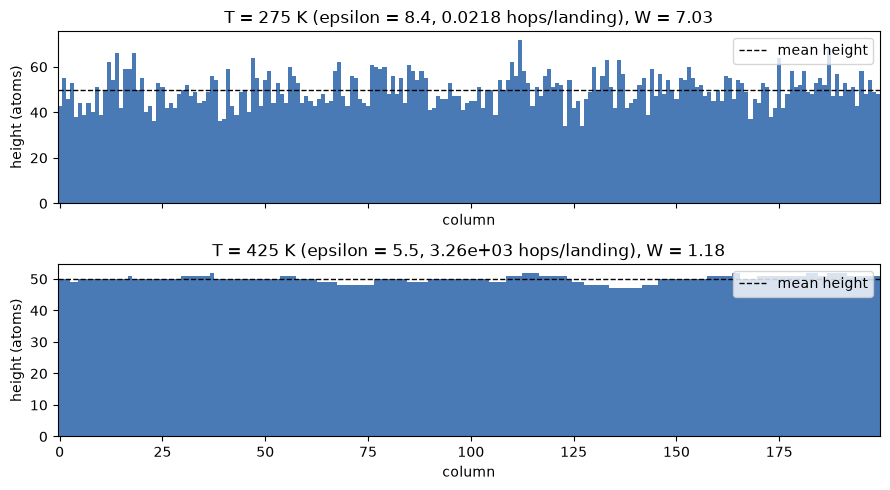

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, temp in zip(axes, (275.0, 425.0)):        # the same two temperatures as results/phase3_profiles
    eps, hops = th.ThermalSettings(temperature=temp).thermal()
    film = np.zeros(200, np.int64)
    th.thermal_grow(film, 50 * 200, eps, hops, 42)
    plot_surface(film, ax=ax, title=f"T = {temp:g} K (epsilon = {eps:.1f}, {hops:.3g} hops/landing), W = {roughness(film):.2f}")
fig.tight_layout(); plt.show()

**What to notice:** at 275 K atoms barely move (0.02 hops per landing) and the film looks like random deposition. At
425 K (thousands of hops) the film is a few flat terraces separated by steps.

### 7b. Sweep 1: the dimensionless model (vary only epsilon)

`sweep_epsilon(settings, epsilons, hops)` fixes 100 hops per landing and varies only the bond strength `epsilon`.
This isolates the role of bonding.

0.9 s
identical to results/phase3_epsilon_sweep/data.csv: True


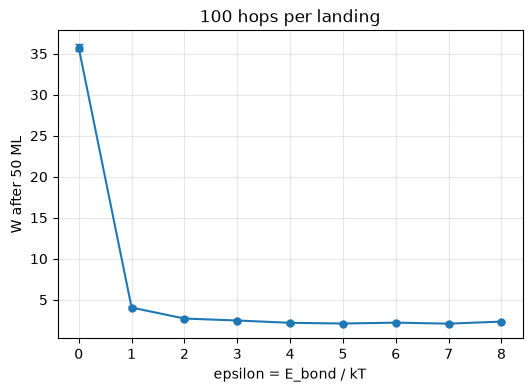

,epsilon,hops_per_landing,roughness,roughness_sem
0,0.0,100.0,35.726,0.392
1,1.0,100.0,4.051,0.176
2,2.0,100.0,2.710,0.166
3,3.0,100.0,2.471,0.120
4,4.0,100.0,2.190,0.123
5,5.0,100.0,2.103,0.118
6,6.0,100.0,2.211,0.084
7,7.0,100.0,2.088,0.086
8,8.0,100.0,2.337,0.099


In [12]:
t0 = time.perf_counter()
eps_df = th.sweep_epsilon(base, np.linspace(0, 8, 9), 100.0)
print(f"{time.perf_counter() - t0:.1f} s")
_, eps_saved = load_saved("phase3_epsilon_sweep")
print("identical to results/phase3_epsilon_sweep/data.csv:", np.allclose(eps_df["roughness"], eps_saved["roughness"]))
ax = plot_sweep(eps_df, "epsilon", "roughness", "roughness_sem", xlabel="epsilon = E_bond / kT", ylabel="W after 50 ML")
ax.set_title("100 hops per landing"); plt.show()
eps_df.round(3)

**What to notice** (saved values): with **no bonding** (`epsilon = 0`) the film is extremely rough, W ≈ 35.7. Atoms
hop uphill as easily as downhill, so mass random-walks between columns. Weak bonding (`epsilon = 1`) already brings W
down to about 4.1, and from `epsilon` ≈ 4 it levels off around 2.1 to 2.3. Smoothing needs atoms that **move and then
stay** once they find a good site.

### 7c. Sweep 2: temperature at fixed flux (1 ML/s)

`sweep_temperature(settings, temperatures)` builds a `ThermalSettings` per temperature, converts to
`(epsilon, hops)` and runs the ensemble; it keeps the final `W` (after 50 ML). This is the slowest cell (high
temperatures mean up to 1e4 hops per landing).

17.6 s
identical to results/phase3_temperature_sweep/data.csv: True


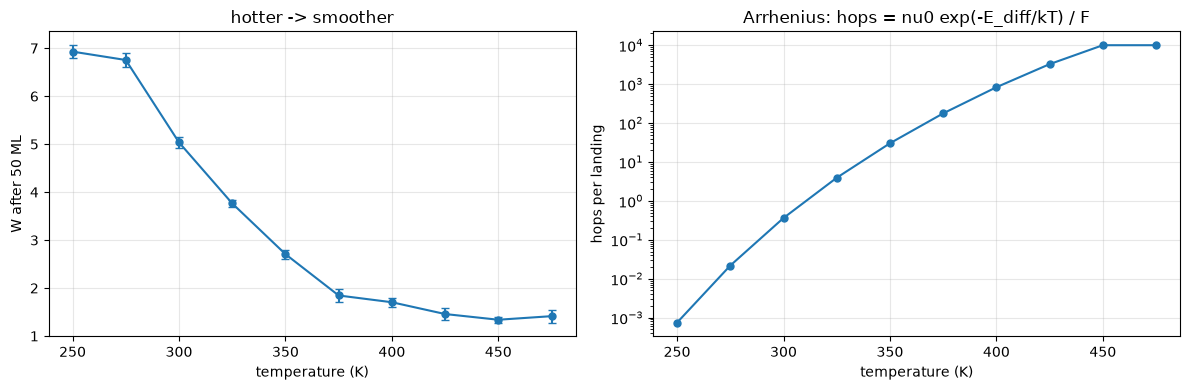

,temperature,epsilon,hops_per_landing,roughness,roughness_sem
0,250.0,9.284,0.001,6.928,0.134
1,275.0,8.440,0.022,6.754,0.153
2,300.0,7.736,0.364,5.036,0.122
3,325.0,7.141,3.930,3.764,0.065
4,350.0,6.631,30.235,2.707,0.093
5,375.0,6.189,177.204,1.845,0.129
6,400.0,5.802,832.614,1.704,0.089
7,425.0,5.461,3261.059,1.458,0.123
8,450.0,5.158,10000.000,1.340,0.059
9,475.0,4.886,10000.000,1.414,0.135


In [13]:
t0 = time.perf_counter()
t_df = th.sweep_temperature(base, np.linspace(250, 475, 10))
print(f"{time.perf_counter() - t0:.1f} s")
_, t_saved = load_saved("phase3_temperature_sweep")
print("identical to results/phase3_temperature_sweep/data.csv:", np.allclose(t_df["roughness"], t_saved["roughness"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_sweep(t_df, "temperature", "roughness", "roughness_sem", ax=axes[0], xlabel="temperature (K)", ylabel="W after 50 ML")
plot_sweep(t_df, "temperature", "hops_per_landing", ax=axes[1], xlabel="temperature (K)", ylabel="hops per landing")
axes[1].set_yscale("log"); axes[0].set_title("hotter -> smoother"); axes[1].set_title("Arrhenius: hops = nu0 exp(-E_diff/kT) / F")
plt.tight_layout(); plt.show()
t_df[["temperature", "epsilon", "hops_per_landing", "roughness", "roughness_sem"]].round(3)

**What to notice** (saved values): W falls from 6.93 at 250 K to 1.34 at 450 K, about 5 times smoother (the README's
"roughness falls 5x from 250 K to 450 K"). On a log axis the hop count rises in a straight line (Arrhenius) until
it hits the 1e4 cap at 450 K. Above the cap hops can no longer increase while bonds keep weakening; the 475 K value
(1.41) is slightly above the 450 K one (1.34), but the difference is within the error bars (`roughness_sem` 0.06 and
0.13), so on this data it could be noise.

### 7d. Sweep 3: deposition rate at fixed temperature (375 K)

8.5 s
identical to results/phase3_flux_sweep/data.csv: True


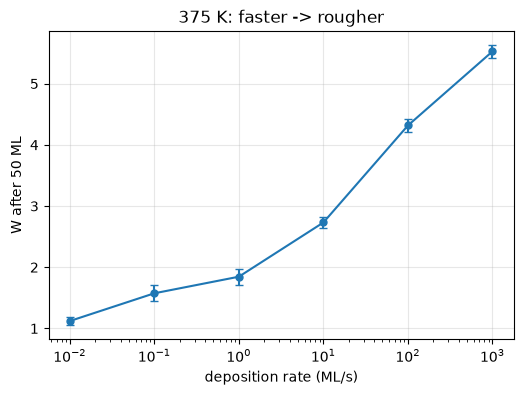

,flux,hops_per_landing,roughness,roughness_sem
0,0.01,10000.000,1.121,0.065
1,0.10,1772.039,1.574,0.133
2,1.00,177.204,1.845,0.129
3,10.00,17.720,2.731,0.097
4,100.00,1.772,4.316,0.109
5,1000.00,0.177,5.527,0.104


In [14]:
t0 = time.perf_counter()
f_df = th.sweep_flux(th.ThermalSettings(**{**asdict(base), "temperature": 375.0}), [0.01, 0.1, 1, 10, 100, 1000])
print(f"{time.perf_counter() - t0:.1f} s")
_, f_saved = load_saved("phase3_flux_sweep")
print("identical to results/phase3_flux_sweep/data.csv:", np.allclose(f_df["roughness"], f_saved["roughness"]))
plot_sweep(f_df, "flux", "roughness", "roughness_sem", logx=True, xlabel="deposition rate (ML/s)", ylabel="W after 50 ML")
plt.title("375 K: faster -> rougher"); plt.show()
f_df[["flux", "hops_per_landing", "roughness", "roughness_sem"]].round(3)

**What to notice** (saved values): from 0.01 to 1000 ML/s (100,000 times faster), W rises from 1.12 to 5.53, about 5
times rougher. Each step to the right divides hops by 10.

## 8. How noisy is one number? Same recipe, three estimates

The recipe 375 K at 1 ML/s, 50 ML, appears in three saved files:

In [15]:
_, pw = load_saved("phase3_process_window")
print("phase3_temperature_sweep (8 runs, 20 points):", round(t_saved.loc[t_saved.temperature == 375, "roughness"].item(), 3))
print("phase3_flux_sweep        (8 runs, 20 points):", round(f_saved.loc[f_saved.flux == 1.0, "roughness"].item(), 3))
print("phase3_process_window    (4 runs,  5 points):",
      round(pw.loc[(pw.temperature == 375) & (pw.flux == 1.0), "roughness"].item(), 3))

phase3_temperature_sweep (8 runs, 20 points): 1.845
phase3_flux_sweep        (8 runs, 20 points): 1.845
phase3_process_window    (4 runs,  5 points): 2.467


The first two are identical (same settings and seed, so the same films). The process window, with 4 runs and a
different number of measurement points (which changes how the random seeds are drawn), says 2.47. Are these
different physics or just noise? Run the same recipe with 6 different master seeds × 8 films each (48 films):

In [16]:
t0 = time.perf_counter()
estimates = [th.run_ensemble(th.ThermalSettings(temperature=375.0, flux=1.0, n_runs=8, n_points=5, seed=sd)).iloc[-1]["roughness_mean"]
             for sd in range(6)]
print(f"{time.perf_counter() - t0:.1f} s")
print("six 8-film estimates:", np.round(estimates, 2))
print(f"mean of 48 films: {np.mean(estimates):.2f}")

0.8 s
six 8-film estimates: [2.25 2.24 2.19 2.06 2.   2.01]
mean of 48 films: 2.12


**What to notice:** the six 8-film estimates range from 2.00 to 2.25 and average 2.12 over 48 films. The saved
1.85 (8 films) and 2.47 (4 films) lie on either side, about 0.3 away, i.e. roughly 2 of their own standard errors
(`roughness_sem` 0.13 and 0.22). Nothing points to different physics; it is sampling noise. Lessons:

* a number from 4 to 8 films is good to a few tenths here, so compare recipes only when they differ by more than that;
* the "2.5 at 375 K / 1 ML/s" quoted in `ideal.py` comes from the noisy 4-film window cell; a bigger ensemble puts
  it nearer 2.1 (the POR is still more than twice as smooth);
* this is why notebook 5 looks at 30 individual wafers before trusting a recipe.

## 9. The process window and the POR

A **process window** is a map of results over a grid of recipes. `process_window()` in `scripts/run_phase3.py` tries
11 temperatures (300 to 550 K) × 6 rates (0.01 to 1000 ML/s) = 66 recipes, each with 4 films (`n_runs = 4`,
`n_points = 5`, 50 ML). We read the saved grid rather than recompute all of it, then recompute one row to check.

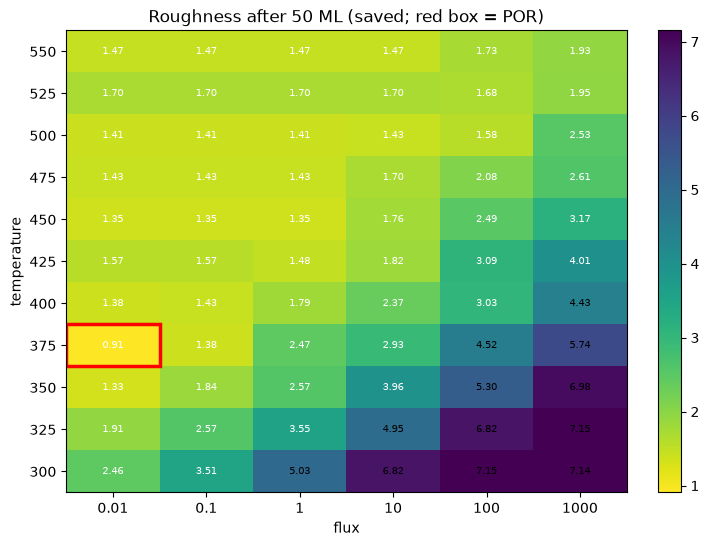

 temperature  flux  hops_per_landing  roughness
         375  0.01         10000.000      0.907
         350  0.01          3023.479      1.330
         450  0.01         10000.000      1.352
         450  0.10         10000.000      1.352
         450  1.00         10000.000      1.352


In [17]:
pivot = pw.pivot(index="temperature", columns="flux", values="roughness")
por = IDEAL["thermal"]["settings"]
ax = plot_heatmap(pivot, cmap="viridis_r", title="Roughness after 50 ML (saved; red box = POR)",
                  highlight=(por["temperature"], por["flux"]))
ax.figure.set_size_inches(8, 6); plt.show()
print(pw.sort_values("roughness").head(5)[["temperature", "flux", "hops_per_landing", "roughness"]].round(3).to_string(index=False))

In [18]:
t0 = time.perf_counter()
grid_base = th.ThermalSettings(n_runs=4, n_points=5)
row = [th.run_ensemble(th.ThermalSettings(**{**asdict(grid_base), "temperature": 375.0, "flux": f})).iloc[-1]["roughness_mean"]
       for f in [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]]
print(f"{time.perf_counter() - t0:.1f} s")
print("recomputed 375 K row:", np.round(row, 3))
print("saved 375 K row     :", np.round(pw[pw.temperature == 375]["roughness"].values, 3))

4.2 s
recomputed 375 K row: [0.907 1.381 2.467 2.93  4.524 5.745]
saved 375 K row     : [0.907 1.381 2.467 2.93  4.524 5.745]


**What to notice:** smooth films are in the hot/slow corner, rough ones in the cold/fast corner, with diagonal bands
in between (hotter lets you go faster at equal roughness). The smoothest saved cell is **375 K at 0.01 ML/s**
(W = 0.91), the red box. Several hotter cells sit at the same value (1.35) across rates: there the hops are capped at
1e4, so the rate no longer matters.

**POR** means *process of record*: the approved default recipe in a fab. The project stores one per model in
`src/thin_film/ideal.py`, with its reasoning:

In [19]:
print(json.dumps(IDEAL["thermal"]["settings"]))
print()
print(IDEAL["thermal"]["why"])

{"temperature": 375, "flux": 0.01, "n_columns": 200, "n_monolayers": 100}

Smoothest film in the grid search (W = 0.91 after 50 ML vs 2.5 at 375 K / 1 ML/s). It is the coolest temperature at which slow deposition still maxes out the hops (1e4 per landing): atoms explore fully while bonds stay strong enough to hold them at good sites. All 30 test wafers passed the spec. Faster alternative: 450 K at 1 ML/s gives W = 1.35 at 100x the deposition rate, but only 24 of 30 wafers pass.


Why is the coolest capped temperature the best? At 375 K and 0.01 ML/s atoms already get the maximum 1e4 hops (lots
of exploration), while `epsilon` is still large (bonds strong enough to hold atoms once they reach a good site).
Going hotter keeps hops at the cap but weakens bonds.

Note: the window ranks recipes at 50 ML, while the POR is used for a **100 ML** film in the app and the yield study.
Notebook 5 checks the POR wafer by wafer.

## 10. Watching a film grow (animation)

`plotting.animate_profiles(frames)` turns a list of height profiles into a matplotlib animation; `gif_bytes` renders
it to a GIF in memory (via a temporary folder that is deleted afterwards, so nothing is saved in the project). Each
frame below adds 1/30 of a 50 ML film at 425 K; the profile is shifted so its lowest column is at 0.

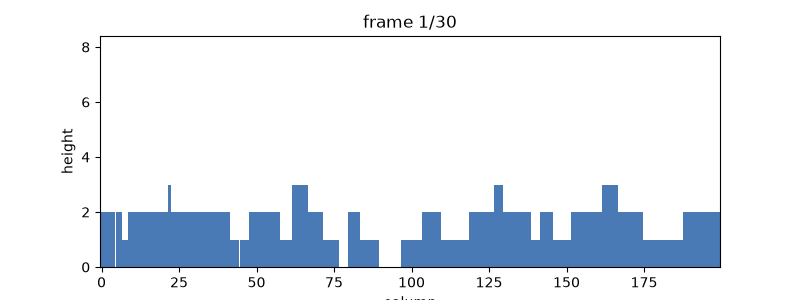

In [20]:
from IPython.display import Image
from thin_film.plotting import animate_profiles, gif_bytes

eps, hops = th.ThermalSettings(temperature=425.0).thermal()
heights, frames = np.zeros(200, np.int64), []
for k in range(30):
    th.thermal_grow(heights, 200 * 50 // 30, eps, hops, k)
    frames.append(heights - heights.min())
anim = animate_profiles(frames); plt.close()
Image(data=gif_bytes(anim))

## 11. How the `results/phase3_*` folders are produced

`PYTHONPATH=src .venv/bin/python scripts/run_phase3.py` runs `main()` then `process_window()` (we did not run it):

| Saved folder | What | Notebook part |
|---|---|---|
| `results/phase3_epsilon_sweep/` | `sweep_epsilon`, epsilon 0..8, 100 hops | 7b |
| `results/phase3_temperature_sweep/` | `sweep_temperature`, 250..475 K, 1 ML/s, plus the hops panel | 7c |
| `results/phase3_flux_sweep/` | `sweep_flux`, 0.01..1000 ML/s at 375 K | 7d |
| `results/phase3_profiles/` | figure only: one film at 275 K and at 425 K | 7a |
| `results/phase3_process_window/` | 66-recipe grid, heatmap with the POR boxed | 9 |

Each `settings.json` also stores the computed `epsilon` and `hops_per_landing` of the base settings next to the
real-unit inputs.

In [21]:
meta, _ = load_saved("phase3_flux_sweep")
print(json.dumps(meta["settings"], indent=1)[:900])

{
 "model": "thermal_hopping",
 "n_columns": 200,
 "n_monolayers": 50,
 "n_runs": 8,
 "n_points": 20,
 "temperature": 375.0,
 "flux": 1.0,
 "e_bond": 0.2,
 "e_diff": 0.8,
 "nu0": 10000000000000.0,
 "max_hops": 10000.0,
 "seed": 42,
 "epsilon": 6.189076331597645,
 "hops_per_landing": 177.20387086305297,
 "fluxes": [
  0.01,
  0.1,
  1,
  10,
  100,
  1000
 ]
}


## 12. Recap and exercises

### What we learned
* Real conditions map onto two knobs: `epsilon = E_bond/kT` (stickiness) and `hops = nu0 exp(-E_diff/kT) / F`
  (moves per arrival, capped at 1e4).
* A hop succeeds with `exp(-n * epsilon)` for `n` side neighbours, so atoms wander until they find steps and grooves.
* Heat smooths and speed roughens, each by about 5 times over the tested ranges, both through the hop count; around
  375 K, +40 K is worth about 10 times more rate.
* Bonding matters as much as mobility: with `epsilon = 0` the film is very rough.
* Small ensembles are noisy: the same recipe can read 1.85 or 2.47 depending on which 4 to 8 films you grew.
* The POR (375 K, 0.01 ML/s) is the smoothest cell of the process window.

### Step → module/function → script map

| Step | Module / function | Script / test |
|---|---|---|
| K, eV, ML/s → epsilon, hops | `units.thermal_parameters`, `ThermalSettings.thermal` | `tests/test_thermal.py::test_unit_conversion` |
| land + hop (compiled) | `thermal.thermal_grow` | `tests/test_thermal.py` (conservation, reproducibility, zero-hop) |
| one film / ensemble | `thermal.simulate`, `thermal.run_ensemble` | |
| sweeps | `thermal.sweep_epsilon`, `sweep_temperature`, `sweep_flux` | `scripts/run_phase3.py::main` |
| process window | loop over `run_ensemble` | `scripts/run_phase3.py::process_window` |
| POR | `ideal.IDEAL["thermal"]` | `tests/test_ideal.py` |
| plots | `plotting.plot_sweep`, `plot_heatmap`, `plot_surface`, `animate_profiles` | |

### Try changing X and see Y
1. In Part 5, set `hops_per_landing=0` in the tiny run. Which notebook-1 result do you get?
2. In Part 3, change `E_DIFF` to 0.7 eV. How many kelvin cooler can you run for the same hops at 1 ML/s?
3. Raise the cap: run `th.run_ensemble(th.ThermalSettings(temperature=475, max_hops=1e5, n_runs=2))`. Does the
   upturn at 475 K disappear? How much longer does it take?
4. Change the neighbour rule in `my_thermal_grow` so only the *left* neighbour counts. What happens to `W`?
5. Grow the POR for 100 ML instead of 50 (`n_monolayers=100`). Is `W` still below the 2.0 spec of notebook 5?

**Next:** notebook 4 moves to a 2D side view of a trench, where the same hopping decides whether a void is trapped.